# Experiment 8: Linear Regression
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program to implement the **Linear Regression** algorithm in Python.

## Theory
Simple linear regression fits `y = m x + c` by minimising the sum of squared errors:

`m = sum((x - x_mean)(y - y_mean)) / sum((x - x_mean)^2)`, `c = y_mean - m x_mean`

Multiple linear regression extends this to many features. Data set: scikit-learn *Diabetes* data (disease progression).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

diab = load_diabetes(as_frame=True)
df = diab.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


From scratch   : y = 998.578 * x + 152.003
scikit-learn   : y = 998.578 * x + 152.003

Test R2  : 0.2334
Test MAE : 52.26
Test RMSE: 63.732


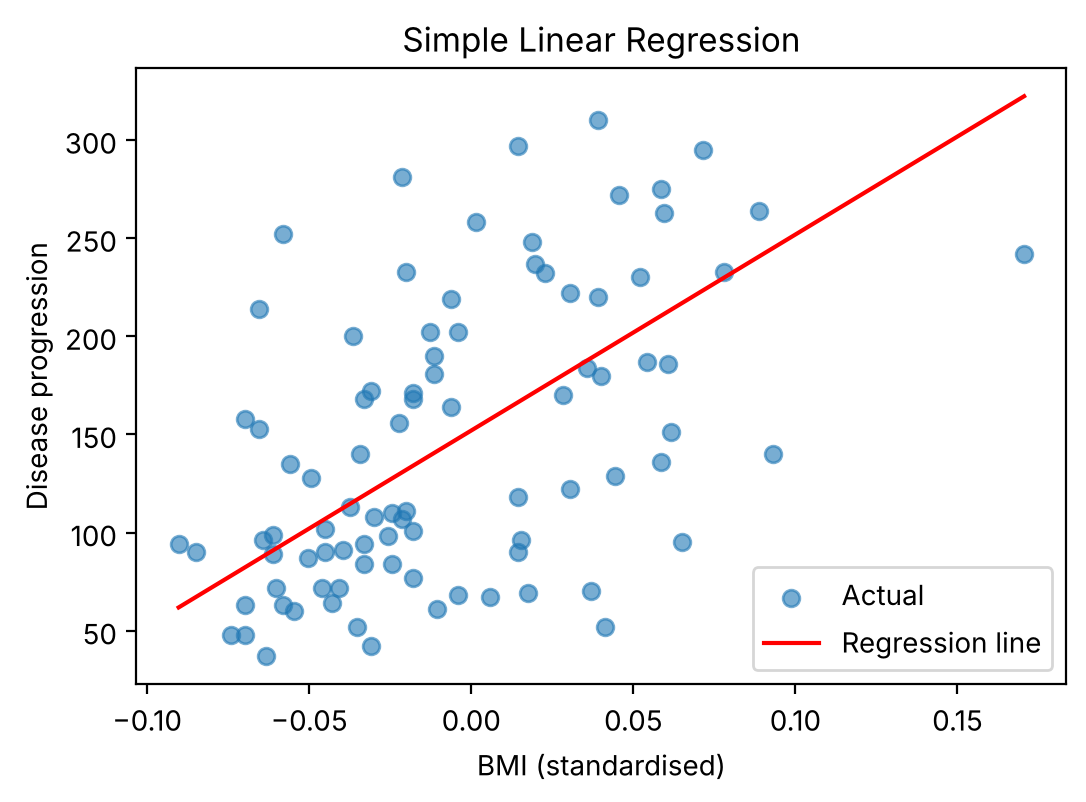

In [2]:
# ---------- Simple linear regression: bmi -> disease progression ----------
x = df['bmi'].values
y = df['target'].values
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=42)

# closed-form least squares
m = np.sum((x_tr - x_tr.mean()) * (y_tr - y_tr.mean())) / np.sum((x_tr - x_tr.mean()) ** 2)
c = y_tr.mean() - m * x_tr.mean()
print(f'From scratch   : y = {m:.3f} * x + {c:.3f}')

lr = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
print(f'scikit-learn   : y = {lr.coef_[0]:.3f} * x + {lr.intercept_:.3f}')

pred = m * x_te + c
print('\nTest R2  :', round(r2_score(y_te, pred), 4))
print('Test MAE :', round(mean_absolute_error(y_te, pred), 3))
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_te, pred)), 3))

plt.figure(figsize=(6, 4))
plt.scatter(x_te, y_te, alpha=0.6, label='Actual')
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, m * xs + c, color='red', label='Regression line')
plt.xlabel('BMI (standardised)'); plt.ylabel('Disease progression'); plt.legend()
plt.title('Simple Linear Regression'); plt.show()

Intercept:

 151.346
age     37.90
sex   -241.96
bmi    542.43
bp     347.70
s1    -931.49
s2     518.06
s3     163.42
s4     275.32
s5     736.20
s6      48.67

Test R2  : 0.4526
Test MAE : 42.794
Test RMSE: 53.853


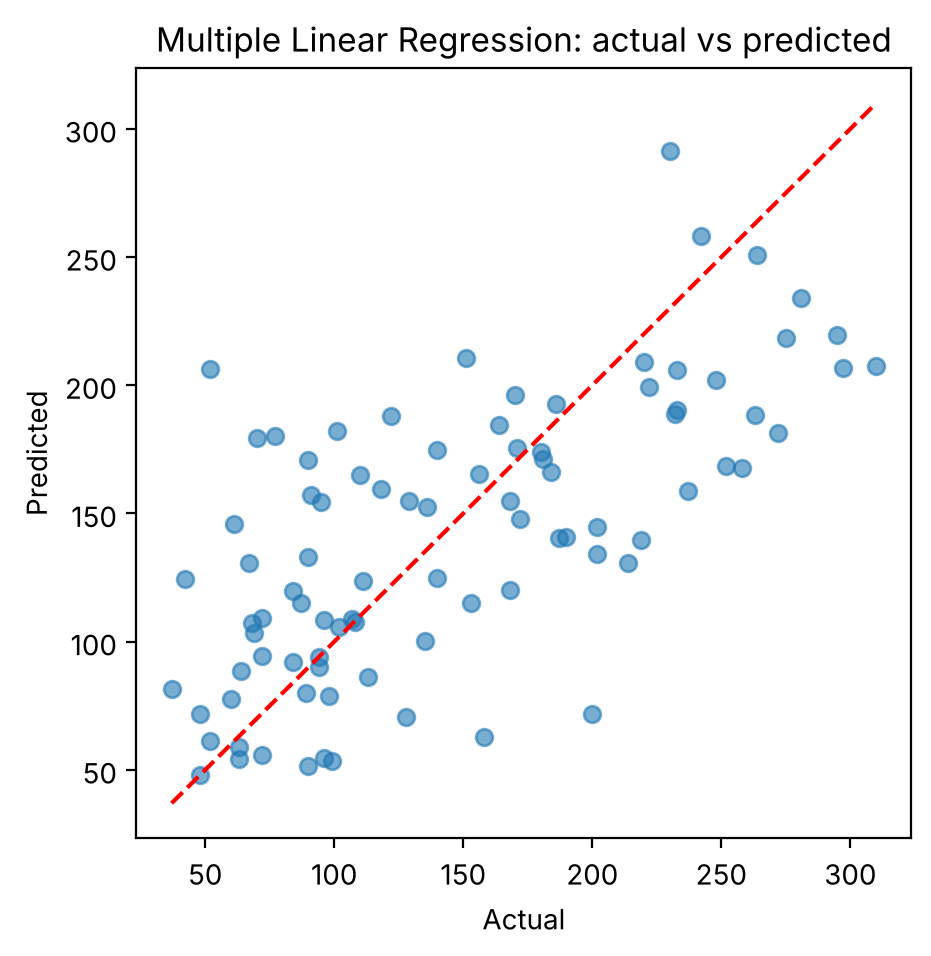

In [3]:
# ---------- Multiple linear regression: all 10 features ----------
X = df.drop(columns='target')
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression().fit(X_tr, y_tr)
pred = mlr.predict(X_te)
print('Intercept:', round(mlr.intercept_, 3))
print(pd.Series(mlr.coef_, index=X.columns).round(2).to_string())
print('\nTest R2  :', round(r2_score(y_te, pred), 4))
print('Test MAE :', round(mean_absolute_error(y_te, pred), 3))
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_te, pred)), 3))

plt.figure(figsize=(5, 5))
plt.scatter(y_te, pred, alpha=0.6)
lims = [y_te.min(), y_te.max()]
plt.plot(lims, lims, 'r--'); plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title('Multiple Linear Regression: actual vs predicted'); plt.show()

## Result
The closed-form least-squares line equals scikit-learn's. A single feature (BMI) explains a modest part of the variance; using all ten features improves R2, as shown by the actual-vs-predicted plot.